In [2]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
import plotly.express as px
import sklearn.metrics as metrics


import warnings
warnings.filterwarnings('ignore')

In [4]:
default=pd.read_csv('Default.csv')

In [5]:
default.head()

,default,student,balance,income
0,No,No,729.526495,44361.625074
1,No,Yes,817.180407,12106.134700
2,No,No,1073.549164,31767.138947
3,No,No,529.250605,35704.493935
4,No,No,785.655883,38463.495879


In [6]:
default.describe()

,balance,income
count,10000.000000,10000.000000
mean,835.374886,33516.981876
std,483.714985,13336.639563
min,0.000000,771.967729
25%,481.731105,21340.462903
50%,823.636973,34552.644802
75%,1166.308386,43807.729272
max,2654.322576,73554.233495


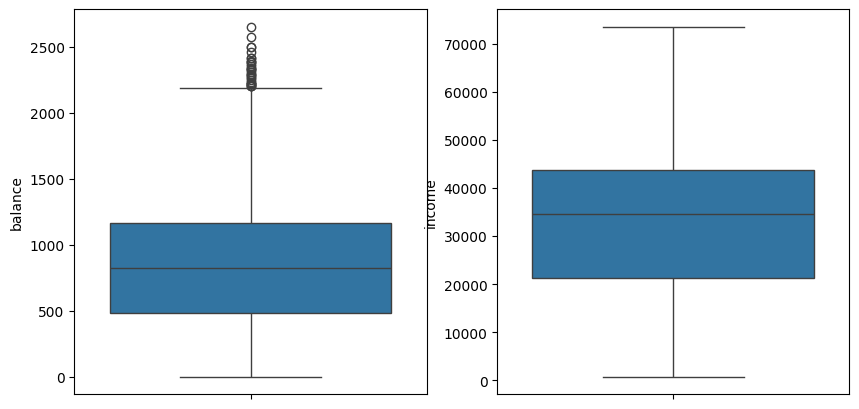

In [7]:
plt.figure(figsize=(10,5))
plt.subplot(1,2,1)
sns.boxplot(y=default['balance'])
plt.subplot(1,2,2)
sns.boxplot(y=default['income'])
plt.show()

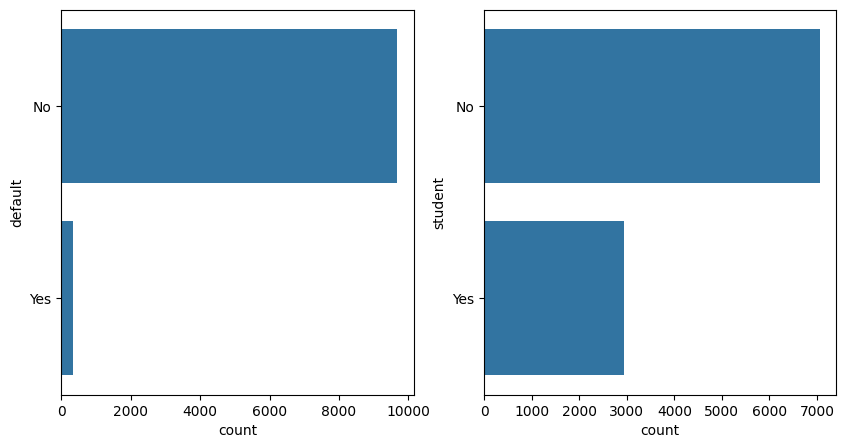

In [8]:
plt.figure(figsize=(10,5))
plt.subplot(1,2,1)
sns.countplot(y=default['default'])
plt.subplot(1,2,2)
sns.countplot(y=default['student'])
plt.show()

In [12]:
default["student"].value_counts()

,count
student,
No,7056
Yes,2944


In [13]:
default['student'].value_counts(normalize=True)

,proportion
student,
No,0.7056
Yes,0.2944


Bi variate Analysis

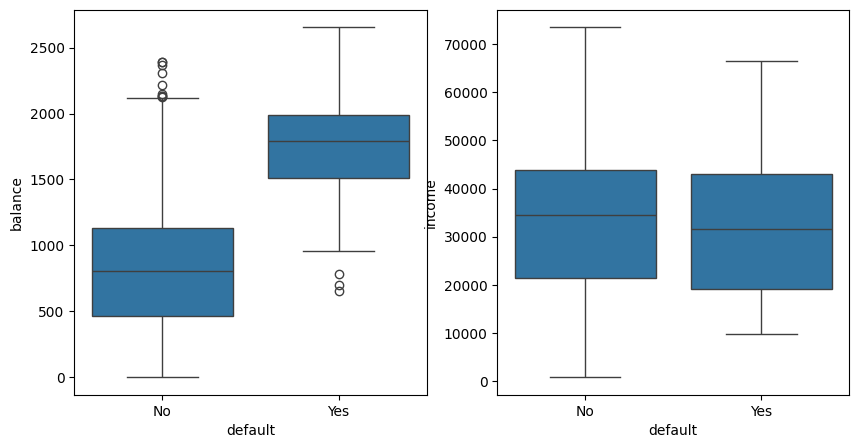

In [14]:
plt.figure(figsize=(10,5))
plt.subplot(1,2,1)
sns.boxplot(x=default['default'],y=default['balance'])
plt.subplot(1,2,2)
sns.boxplot(x=default['default'],y=default['income'])
plt.show()

cross analysis

In [15]:
pd.crosstab(default['student'],default['default'],normalize=True)

default,No,Yes
student,,
No,0.6850,0.0206
Yes,0.2817,0.0127


Correlation between two columns

<Axes: >

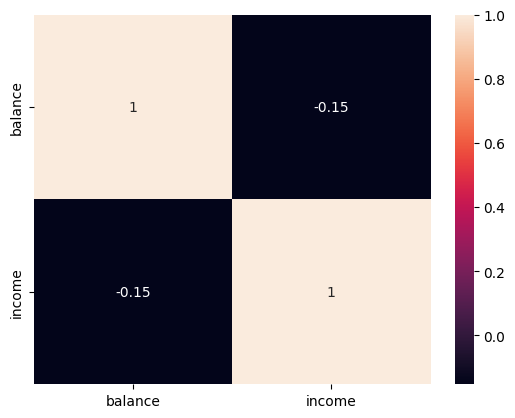

In [16]:
sns.heatmap(default[['balance','income']].corr(),annot=True)

Null values in data set

In [17]:
default.isnull().sum()

,0
default,0
student,0
balance,0
income,0


In [21]:
Q1,Q3=default['balance'].quantile([0.25,0.75])
IQR=Q3-Q1
LL=Q1-(1.5*IQR)
UL=Q3+(1.5*IQR)

Max Val

In [22]:
UL

2193.174308607817

In [23]:
LL

-545.1348170774612

Calculate Outliers

In [24]:
df=default[(default['balance']>UL)]

In [25]:
df

,default,student,balance,income
173,Yes,Yes,2205.799521,14271.492253
1136,Yes,No,2499.016750,51504.293960
1160,Yes,Yes,2502.684931,14947.519752
1359,Yes,No,2220.966201,40725.096207
1502,Yes,Yes,2332.878254,11770.234124
1609,Yes,Yes,2269.946966,18021.105948
2096,Yes,Yes,2261.848162,20030.165119
2140,No,Yes,2308.893236,19110.266412
2929,Yes,Yes,2387.314867,28296.914718
3162,Yes,Yes,2415.316994,17429.503375


In [27]:
df['default'].count()

np.int64(31)

In [28]:
df['default'].value_counts(normalize=True)

,proportion
default,
Yes,0.83871
No,0.16129


in 31 records 83% is defaulters

In [29]:
df['default'].value_counts()

,count
default,
Yes,26
No,5


setting outlier equal to upper limit to handle outlier

In [30]:
default['balance']=np.where(default['balance']>UL,UL,default['balance'])

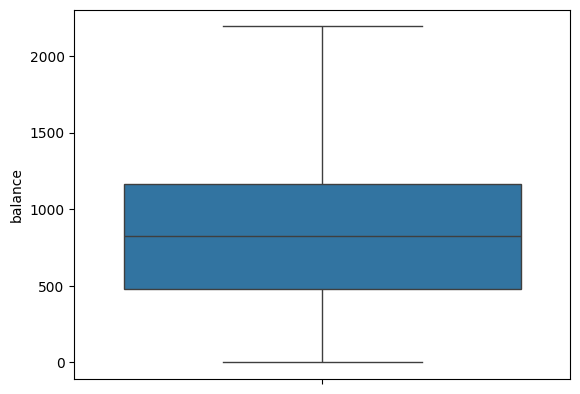

In [31]:
sns.boxplot(y=default['balance'])
plt.show()

convert categorical val to numerical val

In [33]:
default['default']=default['default'].map({'Yes':1,'No':0})
default['student']=default['student'].map({'Yes':1,'No':0})

default=default.astype({'balance':int,'income':int})

In [34]:
default.head()

,default,student,balance,income
0,0,0,729,44361
1,0,1,817,12106
2,0,0,1073,31767
3,0,0,529,35704
4,0,0,785,38463


In [35]:
from sklearn.linear_model import LogisticRegression

in x-axis leave default column and take all other

In [36]:
x=default.drop('default',axis=1)
y=default['default']

stratify used to balance dataset of training and testing

In [37]:
from sklearn.model_selection import train_test_split
x_train,x_test,y_train,y_test=train_test_split(x,y,test_size=0.3,random_state=42,stratify=y)

In [38]:
print(x_train.shape)
print(x_test.shape)
print(y_train.shape)
print(y_test.shape)

(7000, 3)
(3000, 3)
(7000,)
(3000,)


In [39]:
print(y_train.value_counts(normalize=True))
print(y_test.value_counts(normalize=True))

default
0    0.966714
1    0.033286
Name: proportion, dtype: float64
default
0    0.966667
1    0.033333
Name: proportion, dtype: float64


Resampling training set to make ratio 75% and 25%

In [40]:
from imblearn.over_sampling import SMOTE
sm=SMOTE(sampling_strategy=0.75,random_state=33)
x_train,y_train=sm.fit_resample(x_train,y_train)

In [42]:
from sklearn.linear_model import LogisticRegression

In [43]:
lr=LogisticRegression()
lr.fit(x_train,y_train)

LogisticRegression()

In [44]:
y_pred=lr.predict(x_test)

In [45]:
y_pred

array([0, 0, 0, ..., 0, 0, 0], shape=(3000,))

In [46]:
from sklearn.metrics import accuracy_score,confusion_matrix,classification_report

confusion metric is used to calculate accuracy of model prediction


In [47]:
confusion_matrix(y_test,y_pred)

array([[2612,  288],
       [  14,   86]])

In [48]:
(2612+86)/(2612+288+14+86)

0.8993333333333333

y=>student
all other=>x

In [49]:
x=default.drop('student',axis=1)
y=default['student']

In [50]:
from sklearn.model_selection import train_test_split
x_train,x_test,y_train,y_test=train_test_split(x,y,test_size=0.3,random_state=42,stratify=y)

In [51]:
print(x_train.shape)
print(x_test.shape)
print(y_train.shape)
print(y_test.shape)

(7000, 3)
(3000, 3)
(7000,)
(3000,)


In [52]:
print(y_train.value_counts(normalize=True))
print(y_test.value_counts(normalize=True))

student
0    0.705571
1    0.294429
Name: proportion, dtype: float64
student
0    0.705667
1    0.294333
Name: proportion, dtype: float64


In [53]:
from sklearn.linear_model import LogisticRegression

In [54]:
lr=LogisticRegression()
lr.fit(x_train,y_train)

LogisticRegression()

In [55]:
y_pred=lr.predict(x_test)

In [56]:
y_pred

array([0, 0, 1, ..., 0, 0, 1], shape=(3000,))

In [57]:
confusion_matrix(y_test,y_pred)

array([[2013,  104],
       [ 100,  783]])

In [62]:
acc=(2013+783)/(2013+104+100+783)

In [64]:
round(acc,2)

0.93